# Open and use the ISMIP7 store

The ISMIP7 forcing datasets on [source.coop](https://source.coop/ismip) are ~285,000
NetCDF files. The [englacial/ismip7](https://source.coop/englacial/ismip7) Icechunk
stores hold *virtual references* into those files: no data is copied, every group
(`<ESM>/<experiment>/<product>`) is one xarray Dataset with a normalised time axis,
exact standard-grid coordinates and a correct `crs`. Reading is anonymous.

Set `ISMIP7_STORE_AIS` / `ISMIP7_STORE_GRIS` to `local:/path/to/repo` to run these
notebooks against a local dev store.


In [1]:
import os
import time

from ismip7_helper.access import list_groups, store_target


def read(a, tries=3):
    """Load a lazy array and return the seconds taken; retry on transient object-store errors."""
    for attempt in range(tries):
        t0 = time.time()
        try:
            a.load()
            return round(time.time() - t0, 2)
        except Exception as e:
            if attempt == tries - 1:
                raise
            print("retry after", type(e).__name__)


REGION = os.environ.get("ISMIP7_NB_REGION", "AIS")
print("store:", store_target(REGION).url)
groups = list_groups(REGION)
print(len(groups), "groups; first:", groups[:5])
GROUP = os.environ.get("ISMIP7_NB_GROUP", groups[0])

store: local:/tmp/claude-0/-home-user-ismip7-indexing/c378e836-2097-52d9-9f11-06a02384e3a8/scratchpad/devstore/icechunk-ais


  2026-11-01T00:57:23.917561Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343



2 groups; first: ['CESM2-WACCM/historical/SDBN1-8000m', 'CESM2-WACCM/historical/ocean']


## One group as a Dataset

Time is `days since 1850-01-01` (standard calendar) decoded to datetime64; `x`/`y` are the exact ISMIP7 grid; `crs` carries the EPSG code and WKT.

In [2]:
from ismip7_helper.access import open_group

ds = open_group(REGION, GROUP)
ds

  2026-11-01T00:57:25.352125Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343



<xarray.Dataset> Size: 167MB
Dimensions:  (time: 36, y: 761, x: 761)
Coordinates:
  * time     (time) datetime64[ns] 288B 1850-01-15 1850-02-15 ... 1852-12-15
  * y        (y) float64 6kB -3.04e+06 -3.032e+06 ... 3.032e+06 3.04e+06
  * x        (x) float64 6kB -3.04e+06 -3.032e+06 ... 3.032e+06 3.04e+06
    crs      int32 4B ...
Data variables:
    acabf    (time, y, x) float32 83MB ...
    tas      (time, y, x) float32 83MB ...
Attributes: (12/21)
    Conventions:            CF-1.6
    institution:            ULiege (Brice Noel)
    grid:                   Map Projection: Polar Stereographic South EPSG303...
    regrid_method:          conservative
    spatial_resolution:     8000 m
    comment:                Prepared for ISMIP7 by Devon Dunmire using xesmf ...
    ...                     ...
    ismip7_file_version:    v2
    ismip7_group:           CESM2-WACCM/historical/SDBN1-8000m
    ismip7_n_source_files:  6
    source_keys_prefix:     ismip/ismip7-ais-forcing/data/CESM2-WACCM/histori...
    source_time_units:      days since 1850-01-01 00:00:00
    source_time_calendar:   standard

In [3]:
print(ds.attrs.get("ismip7_grid"), "|", ds["crs"].attrs["epsg_code"])
print("time:", str(ds.time.values[0])[:10], "->", str(ds.time.values[-1])[:10], dict(ds.sizes))

AIS 8000 m (EPSG:3031) | EPSG:3031
time: 1850-01-15 -> 1852-12-15 {'time': 36, 'y': 761, 'x': 761}


## Plot one month

Only the chunk for that timestep is fetched from the source file (fill value is masked to NaN).

acabf t=0 read in 0.72s; finite cells 244763


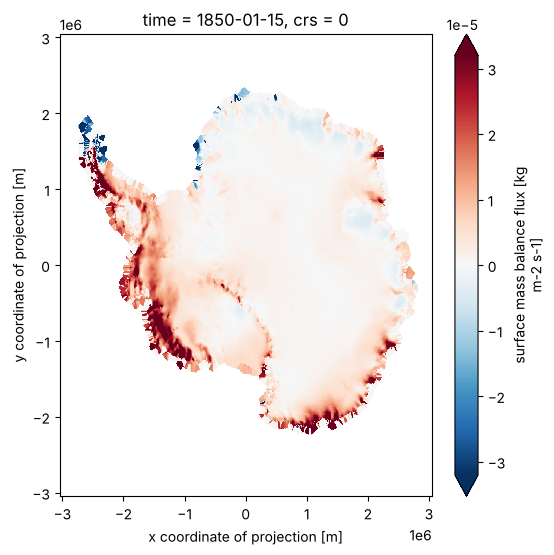

In [4]:
import numpy as np

var = next(v for v in ds.data_vars if ds[v].ndim >= 3)
field = ds[var].isel(time=0)
secs = read(field)
print(f"{var} t=0 read in {secs:.2f}s; finite cells {int(np.isfinite(field).sum())}")
field.plot(x="x", y="y", robust=True, figsize=(6, 6));

## Subset and reduce

A spatial window and an annual mean over the first year; everything stays lazy until `.compute()`.

In [5]:
win = ds[var].isel(time=slice(0, 12)).sel(x=slice(None, None, 4), y=slice(None, None, 4))
annual = win.mean("time").compute()
print(annual.shape, float(np.nanmean(annual)))

(191, 191) 6.050296178727876e-06


## The whole store as a DataTree

`open_store` walks every group; with many groups prefer `engine='rustytree'` (next notebook).

In [6]:
from ismip7_helper.access import open_store

t0 = time.time()
dt = open_store(REGION)
print(f"{sum(1 for _ in dt.subtree)} nodes in {time.time() - t0:.2f}s")
print([g.path for g in dt.subtree if g.data_vars][:10])

5 nodes in 0.06s
['/CESM2-WACCM/historical/SDBN1-8000m', '/CESM2-WACCM/historical/ocean']


  2026-11-01T00:57:27.921498Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343

